In [26]:
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from keras.models import Model
from keras.layers import Input, Conv1D, DepthwiseConv1D, BatchNormalization, ReLU, GlobalAveragePooling1D, Dense
from keras.optimizers import Adam
from keras.utils import plot_model


In [28]:
# Load the preprocessed dataset
df = pd.read_csv('../Edge-IIoTset_DNN-112.csv')

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [30]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [31]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [32]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [33]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [34]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [35]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [36]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
8               tcp.ack_raw  3.090813e+14
7                   tcp.ack  1.448397e+14
18                  tcp.seq  7.310286e+12
20               udp.stream  9.184477e+11
4   icmp.transmit_timestamp  1.689471e+11
..                      ...           ...
89                  mqtt1_8  1.169939e+00
84                  mqtt1_3  7.799595e-01
85                  mqtt1_4  7.799595e-01
90                  mqtt1_9  7.799595e-01
91                 mqtt1_10  7.799595e-01

[97 rows x 2 columns]


In [37]:
selected_features = chi_scores['feature'].tolist()[:93]  # Select top k features

In [38]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [39]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1361814, 93)
X_val shape: (194545, 93)
X_test shape: (389090, 93)


In [40]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [41]:
# Initialize the MobileNet-1D classifier
def mobilenet_1d(input_shape, num_classes):
    inputs = Input(shape=input_shape)

    # Initial Conv1D layer
    x = Conv1D(32, kernel_size=3, strides=2, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Depthwise Separable Convolution block
    x = DepthwiseConv1D(kernel_size=3, padding='same')(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = Conv1D(64, kernel_size=1, padding='same')(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Additional blocks can be added here following the MobileNetV2 structure

    # Global Average Pooling and Output
    x = GlobalAveragePooling1D()(x)

    if num_classes == 2:
        outputs = Dense(1, activation='sigmoid')(x)
        loss = 'binary_crossentropy'
    else:
        outputs = Dense(num_classes, activation='softmax')(x)
        loss = 'sparse_categorical_crossentropy'

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(), loss=loss, metrics=['accuracy'])
    return model


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 93, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 47, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 47, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 47, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv1d_1              │ (None, 47, 32)         │           128 │
│ (DepthwiseConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 47, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 47, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 47, 64)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 47, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 47, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,270 (12.77 KB)

 Trainable params: 3,014 (11.77 KB)

 Non-trainable params: 256 (1.00 KB)

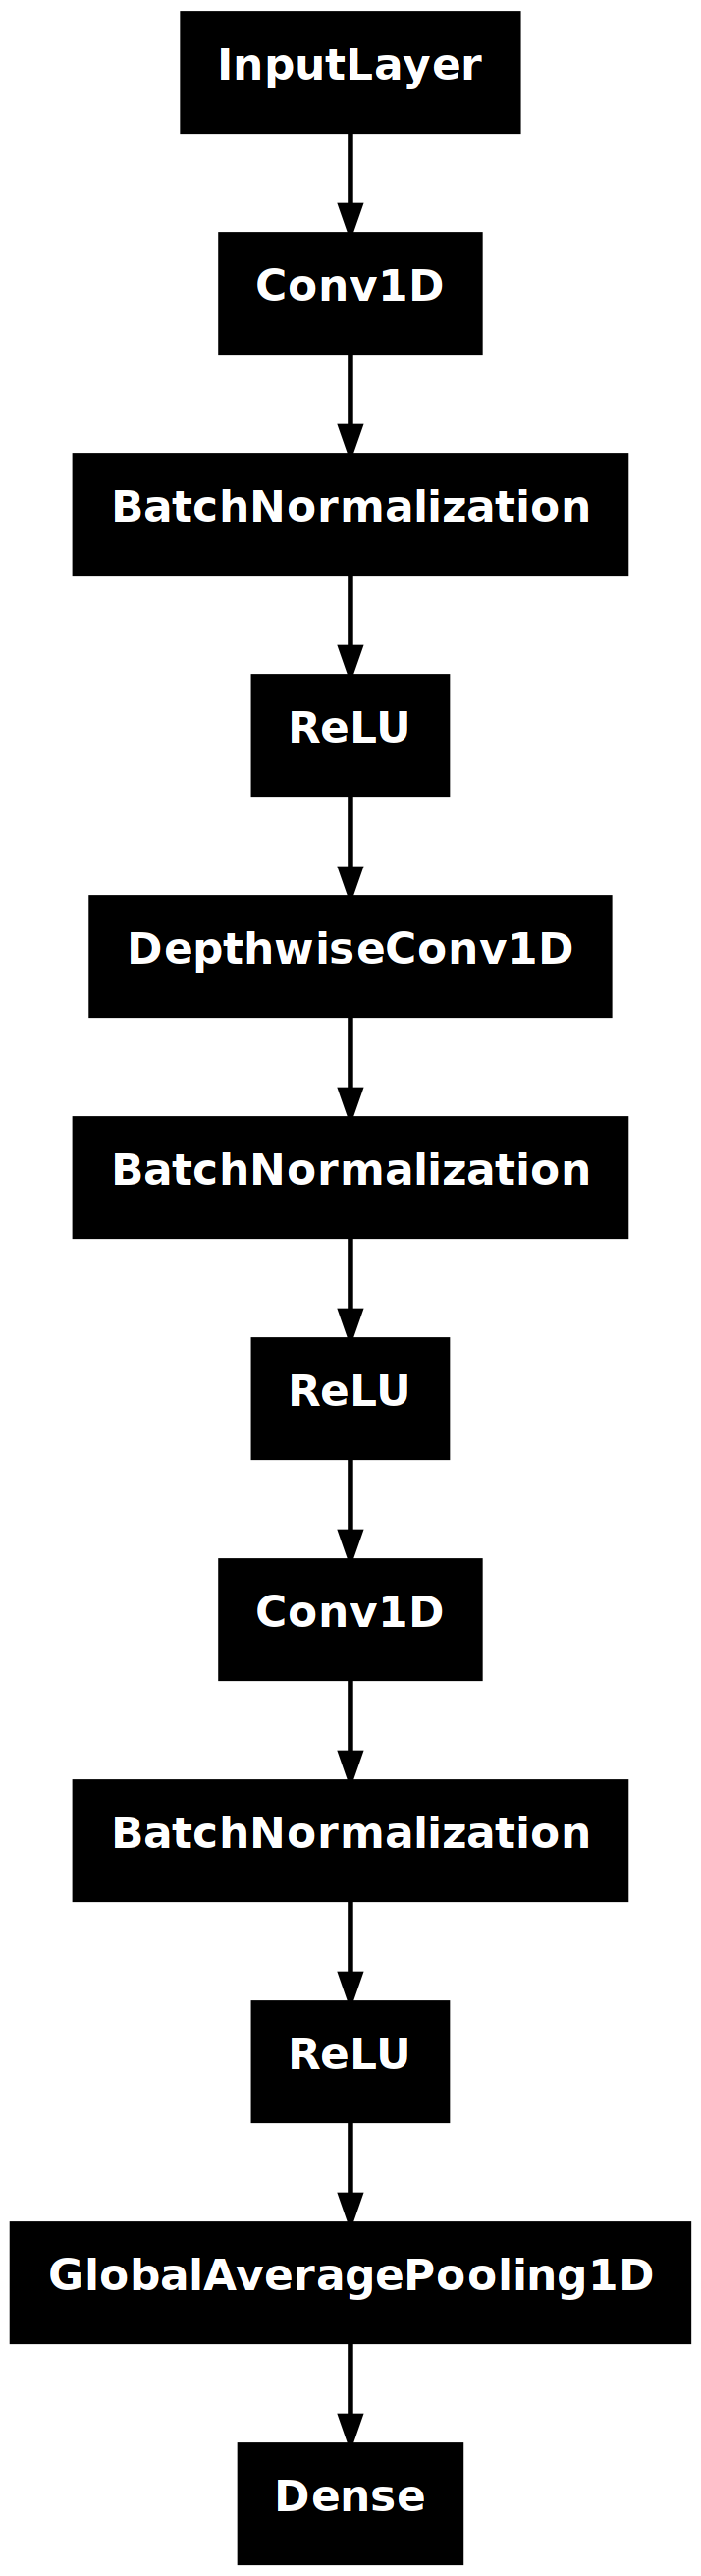

In [42]:
input_shape = (X_train.shape[1], 1)
num_classes = 6
model = mobilenet_1d(input_shape=input_shape, num_classes=num_classes)
model.summary()
plot_model(model)

In [43]:
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = {
    np.int64(cls): weight for cls, weight in zip(np.unique(y_train), class_weights)
}
sample_weights = np.array([class_weights_dict[label] for label in y_train])


In [44]:
train_start_time = time.time()
# Train the model
# history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=32, sample_weight=sample_weights)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=32)

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 96s 2ms/step - accuracy: 0.9423 - loss: 0.1471 - val_accuracy: 0.9530 - val_loss: 0.1380
Epoch 2/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 91s 2ms/step - accuracy: 0.9594 - loss: 0.0887 - val_accuracy: 0.9607 - val_loss: 0.1039
Epoch 3/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 91s 2ms/step - accuracy: 0.9611 - loss: 0.0839 - val_accuracy: 0.9613 - val_loss: 0.1326
Epoch 4/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 92s 2ms/step - accuracy: 0.9617 - loss: 0.0812 - val_accuracy: 0.9608 - val_loss: 0.1021
Epoch 5/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 92s 2ms/step - accuracy: 0.9624 - loss: 0.0793 - val_accuracy: 0.9393 - val_loss: 0.1429
Epoch 6/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 92s 2ms/step - accuracy: 0.9626 - loss: 0.0781 - val_accuracy: 0.9554 - val_loss: 0.1278
12160/12160 ━━━━━━━━━━━━━━━━━━━━ 18s 1ms/step - accuracy: 0.9553 - loss: 0.1223
Test Loss: 0.1242
Test Accuracy: 0.9549
Training time: 554.52 seconds
Testing time: 17.74 seconds


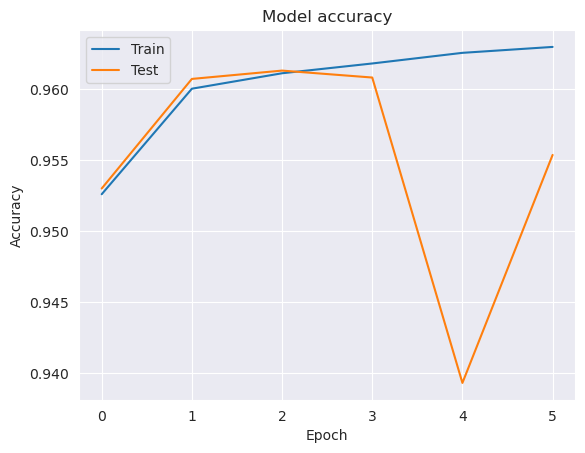

In [45]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

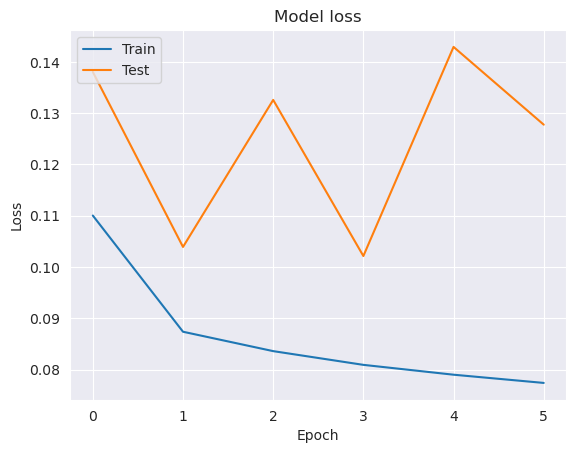

In [46]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [47]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

12160/12160 ━━━━━━━━━━━━━━━━━━━━ 18s 1ms/step


In [48]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    280115
        DDoS       0.87      1.00      0.93     57299
    Scanning       0.98      0.67      0.79     14141
   Injection       0.67      0.85      0.75     20702
        MITM       0.31      0.91      0.46        69
     Malware       0.99      0.42      0.59     16764

    accuracy                           0.95    389090
   macro avg       0.80      0.81      0.75    389090
weighted avg       0.96      0.95      0.95    389090



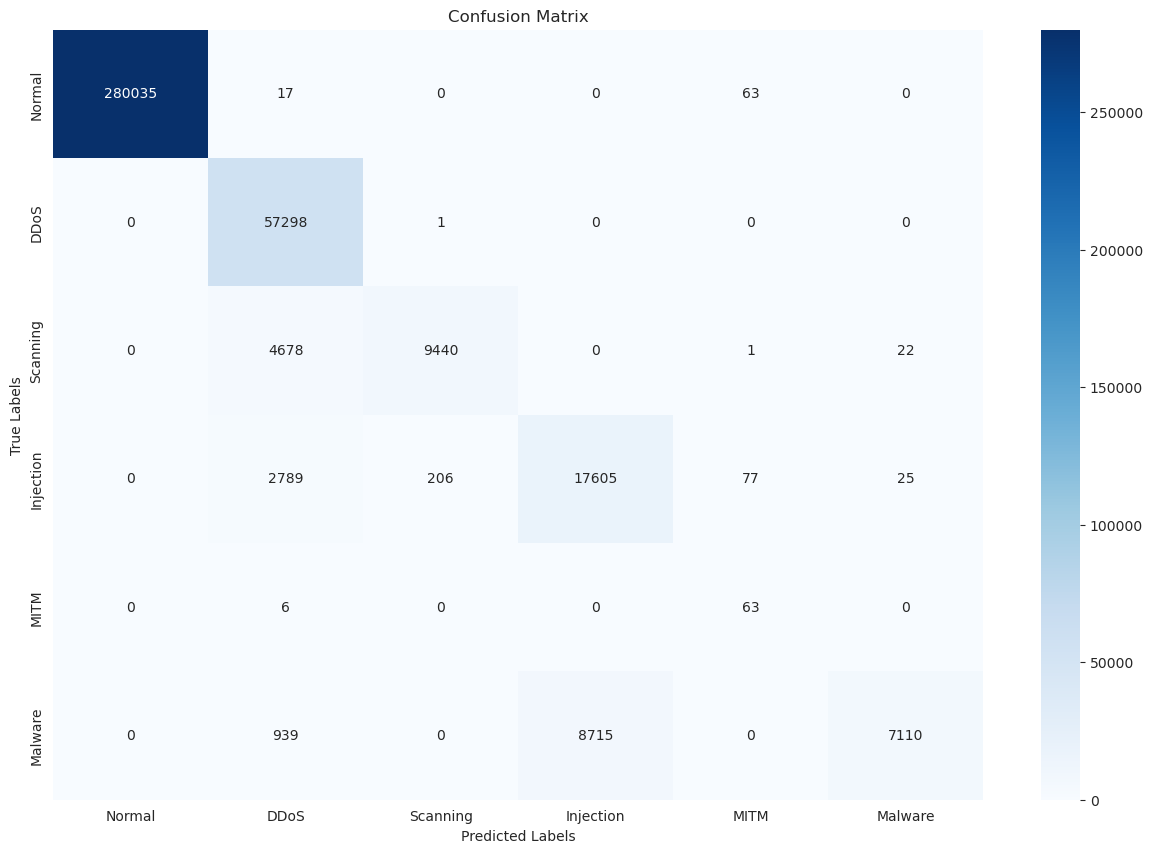

In [49]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

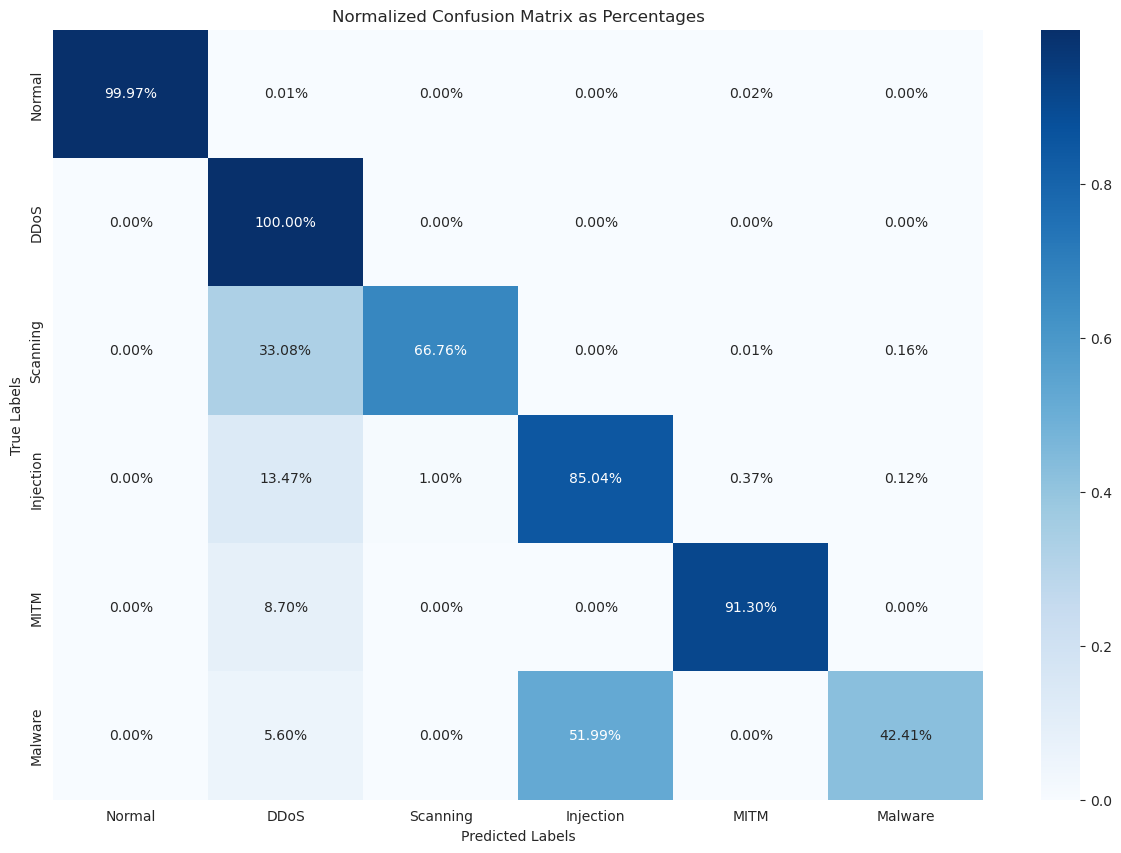

In [50]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')